# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [ ]:
# TODO 1.1 — procentul de valori lipsă pe coloană


# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [2]:

missing_percentage = df.isna().mean() * 100
print("Procentul de valori lipsă pe coloană:")
print(missing_percentage)


cols_to_drop = missing_percentage[missing_percentage > 50].index
df = df.drop(columns=cols_to_drop)


print("\nColoanele rămase după eliminare:")
print(df.columns)

Procentul de valori lipsă pe coloană:
survived     0.000000
pclass       0.000000
sex          0.000000
age         19.865320
fare         0.000000
embarked     0.224467
deck        77.216611
dtype: float64

Coloanele rămase după eliminare:
Index(['survived', 'pclass', 'sex', 'age', 'fare', 'embarked'], dtype='object')


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness (asimetria) pentru fare: 4.7873
Skewness (asimetria) pentru log_fare: 0.3949


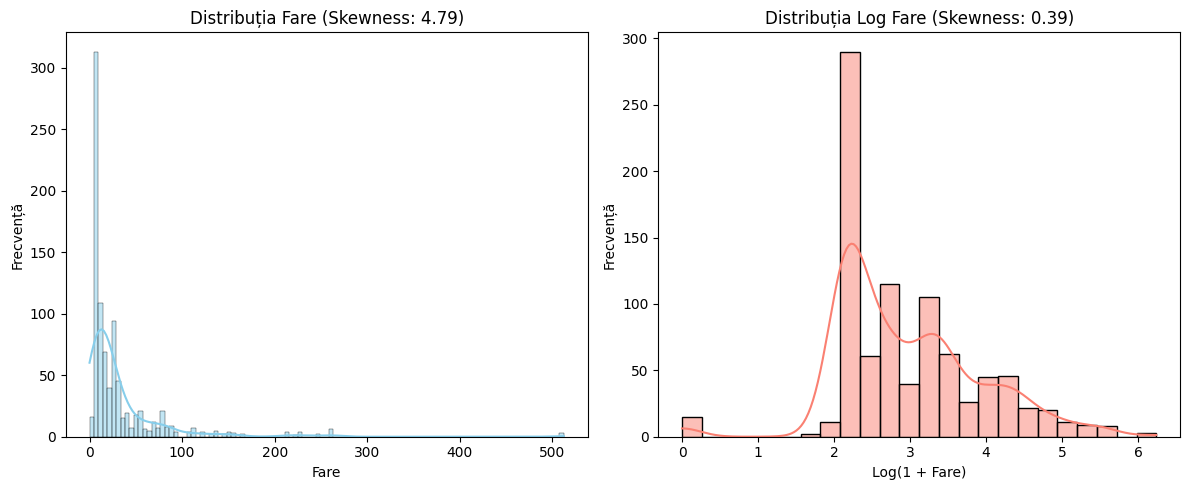

In [3]:


skew_fare = df['fare'].skew()
print(f"Skewness (asimetria) pentru fare: {skew_fare:.4f}")

# TODO 3.2 — coloana log_fare + skewness

df['log_fare'] = np.log1p(df['fare'])
skew_log_fare = df['log_fare'].skew()
print(f"Skewness (asimetria) pentru log_fare: {skew_log_fare:.4f}")

# TODO 3.3 — două histograme
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


sns.histplot(df['fare'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title(f"Distribuția Fare (Skewness: {skew_fare:.2f})")
axes[0].set_xlabel("Fare")
axes[0].set_ylabel("Frecvență")

sns.histplot(df['log_fare'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title(f"Distribuția Log Fare (Skewness: {skew_log_fare:.2f})")
axes[1].set_xlabel("Log(1 + Fare)")
axes[1].set_ylabel("Frecvență")

plt.tight_layout()
plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [4]:
# TODO 4.1 — limite IQR + număr de outlieri
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['fare'] < lower_bound) | (df['fare'] > upper_bound)]
num_outliers = len(outliers)

print(f"Limita inferioară: {lower_bound:.4f}")
print(f"Limita superioară: {upper_bound:.4f}")
print(f"Număr de outlieri pentru 'fare': {num_outliers}")

# TODO 4.2 — fare_capped (clip) + maxim înainte/după
max_before = df['fare'].max()


df['fare_capped'] = df['fare'].clip(lower=lower_bound, upper=upper_bound)

max_after = df['fare_capped'].max()

print(f"Valoarea maximă 'fare' înainte de capping: {max_before:.4f}")
print(f"Valoarea maximă 'fare_capped' după capping: {max_after:.4f}")

Limita inferioară: -26.7240
Limita superioară: 65.6344
Număr de outlieri pentru 'fare': 116
Valoarea maximă 'fare' înainte de capping: 512.3292
Valoarea maximă 'fare_capped' după capping: 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [6]:
## TODO 5.1 — One-Hot Encoding pentru sex și embarked

df_encoded = pd.get_dummies(df, columns=['sex', 'embarked'], drop_first=True, dtype=int)

print("Coloanele rezultate după One-Hot Encoding:")
print(df_encoded.columns.tolist())


# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
scaler = StandardScaler()



df_encoded[['age', 'fare_capped']] = scaler.fit_transform(df_encoded[['age', 'fare_capped']])


print("\nVerificare după Standard Scaling:")
print(f"Medie age: {df_encoded['age'].mean():.4f} | Std age: {df_encoded['age'].std():.4f}")
print(f"Medie fare_capped: {df_encoded['fare_capped'].mean():.4f} | Std fare_capped: {df_encoded['fare_capped'].std():.4f}")

Coloanele rezultate după One-Hot Encoding:
['survived', 'pclass', 'age', 'fare', 'log_fare', 'fare_capped', 'sex_male', 'embarked_Q', 'embarked_S']

Verificare după Standard Scaling:
Medie age: 0.0000 | Std age: 1.0007
Medie fare_capped: 0.0000 | Std fare_capped: 1.0006


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

Am eliminat deck pentru că îi lipseau peste 77% din date și am fi stat mai mult să ghicim decât să lucrăm cu date reale. În schimb, la age lipseau doar 20% din valori și era mult prea importantă pentru predicție (regula „copiii primii”) ca să renunțăm la ea.*Răspunsul tău:*